# Exercise 2 Training an Autoencoder

I trained an autoencoder to reconstruct MNIST images. I used mean squared error (MSE) to measure the difference between the original and reconstructed pixels. I also tracked pixel accuracy by applying a threshold of 0.5 to both images and measuring the percentage of matching pixels.

In [1]:
import matplotlib.pyplot as plt
import tensorflow as tf

(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()
x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test.reshape(-1, 784).astype("float32") / 255.0

## Data split and training setup

I used 54,000 of the 60,000 MNIST training images to train the model and reserved the last 6,000 (10%) for validation. Keras made this split before shuffling the training images. I measured loss and pixel accuracy on the validation images after each epoch. I kept the official test set of 10,000 images separate and used the same eight images for every reconstruction and denoising comparison.

I trained for 100 epochs with batches of 256. I saved the model's outputs at epochs 1, 10, 50, 80, and 100. I added Gaussian noise with a standard deviation of 0.25 to the test images once and clipped their pixel values to the range from 0 to 1. Using the same noisy images at every checkpoint helped me see how the outputs changed during training.

In [2]:
def pixel_accuracy(target, reconstruction):
    matches = tf.equal(target >= 0.5, reconstruction >= 0.5)
    return tf.reduce_mean(tf.cast(matches, tf.float32), axis=-1)

autoencoder = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu", name="bottleneck"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(784, activation="sigmoid"),
])

autoencoder.compile(optimizer="adam", loss="mse", metrics=[pixel_accuracy])

checkpoint_epochs = (1, 10, 50, 80, 100)
originals = x_test[:8]
noisy = tf.clip_by_value(
    originals + tf.random.stateless_normal(originals.shape, seed=(1, 0), stddev=0.25),
    0.0,
    1.0,
)
checkpoints = {}

def save_reconstructions(epoch, logs):
    if epoch + 1 in checkpoint_epochs:
        checkpoints[epoch + 1] = (
            autoencoder(originals, training=False).numpy(),
            autoencoder(noisy, training=False).numpy(),
        )

history = autoencoder.fit(
    x_train,
    x_train,
    epochs=checkpoint_epochs[-1],
    batch_size=256,
    validation_split=0.1,
    callbacks=[tf.keras.callbacks.LambdaCallback(on_epoch_end=save_reconstructions)],
    verbose=2,
)

Epoch 1/100


211/211 - 4s - 19ms/step - loss: 0.0671 - pixel_accuracy: 0.8795 - val_loss: 0.0390 - val_pixel_accuracy: 0.9215


Epoch 2/100


211/211 - 2s - 9ms/step - loss: 0.0321 - pixel_accuracy: 0.9331 - val_loss: 0.0271 - val_pixel_accuracy: 0.9413


Epoch 3/100


211/211 - 2s - 9ms/step - loss: 0.0246 - pixel_accuracy: 0.9453 - val_loss: 0.0223 - val_pixel_accuracy: 0.9492


... (190 outputs left out)

Epoch 99/100


211/211 - 2s - 10ms/step - loss: 0.0068 - pixel_accuracy: 0.9776 - val_loss: 0.0071 - val_pixel_accuracy: 0.9768


Epoch 100/100


211/211 - 2s - 10ms/step - loss: 0.0068 - pixel_accuracy: 0.9776 - val_loss: 0.0070 - val_pixel_accuracy: 0.9772


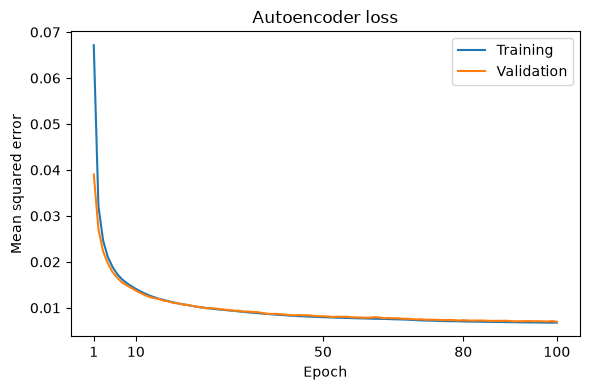

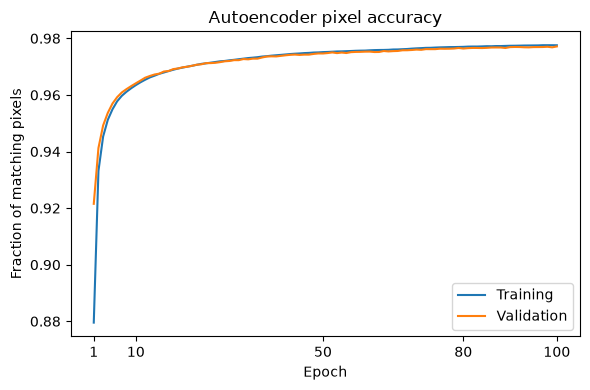

In [3]:
epochs = range(1, len(history.epoch) + 1)

plt.figure(figsize=(6, 4))
plt.plot(epochs, history.history["loss"], label="Training")
plt.plot(epochs, history.history["val_loss"], label="Validation")
plt.title("Autoencoder loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.xticks(checkpoint_epochs)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(epochs, history.history["pixel_accuracy"], label="Training")
plt.plot(epochs, history.history["val_pixel_accuracy"], label="Validation")
plt.title("Autoencoder pixel accuracy")
plt.xlabel("Epoch")
plt.ylabel("Fraction of matching pixels")
plt.xticks(checkpoint_epochs)
plt.legend()
plt.tight_layout()
plt.show()

## Training results

Most of the improvement came early. Validation MSE fell from 0.0390 at epoch 1 to 0.0138 at epoch 10. It kept improving more slowly, reaching 0.0082 at epoch 50, 0.0073 at epoch 80, and 0.0070 at epoch 100. Validation pixel accuracy rose from 92.15% to 97.72% over the run.

At epoch 100, the training MSE was 0.0068 and the validation MSE was 0.0070. The training and validation curves stayed close after the first few epochs and flattened toward the end. The accuracy includes the dark background pixels, so I used the image grids to see how well the model kept the actual digit strokes.

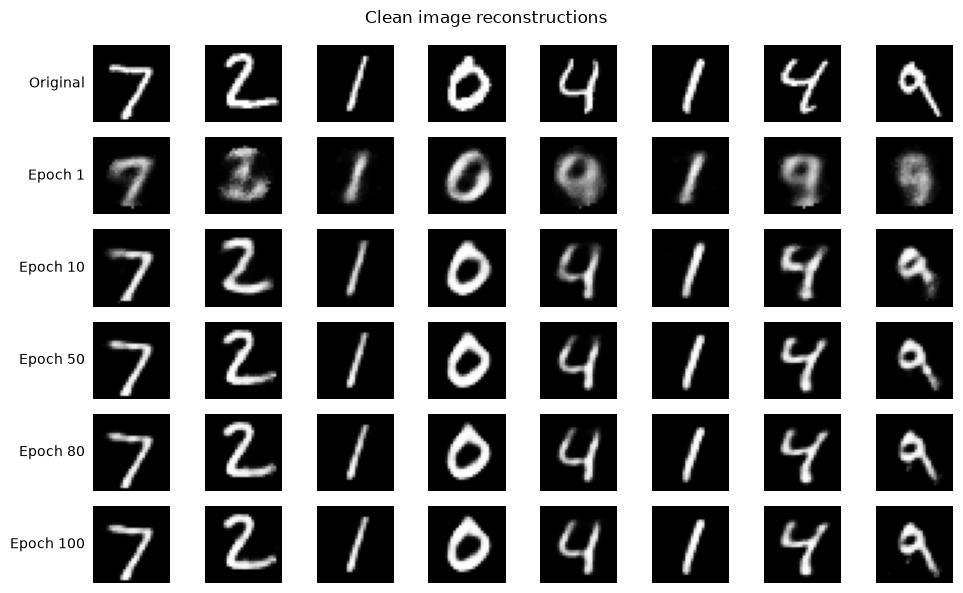

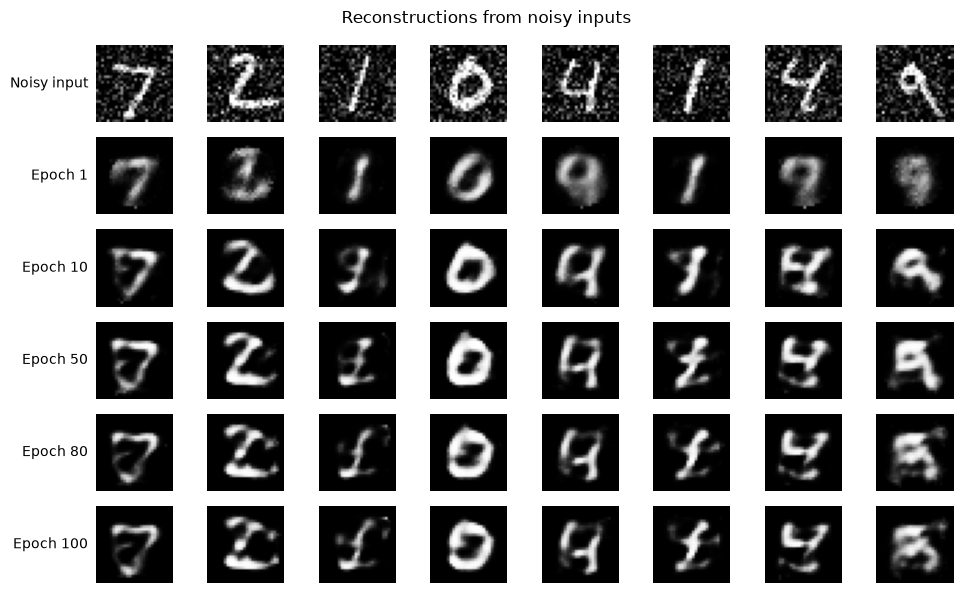

In [4]:
def show_comparison(title, input_label, inputs, outputs):
    rows = [(input_label, inputs)] + [
        (f"Epoch {epoch}", images) for epoch, images in zip(checkpoint_epochs, outputs)
    ]
    fig, axes = plt.subplots(len(rows), len(inputs), figsize=(10, 6))
    fig.suptitle(title)
    for row, (label, images) in enumerate(rows):
        for ax, image in zip(axes[row], images):
            ax.imshow(image.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
            ax.set_axis_off()
        axes[row, 0].text(
            -0.1, 0.5, label, transform=axes[row, 0].transAxes, ha="right", va="center"
        )
    fig.tight_layout()
    plt.show()

reconstructions, denoised = zip(*checkpoints.values())
show_comparison("Clean image reconstructions", "Original", originals, reconstructions)
show_comparison("Reconstructions from noisy inputs", "Noisy input", noisy.numpy(), denoised)

## Reconstruction and denoising results

At epoch 1, the clean reconstructions were blurry, and both 4s looked more like 9s. By epoch 10, the digit shapes were clearer. At epoch 50, the rightmost 9 had a thinner tail that more closely followed the original. The clean reconstructions at epochs 80 and 100 looked very similar.

The model removed much of the background speckling from the noisy images. Some noisy digits were reconstructed more clearly at epoch 10 than at later checkpoints. At epoch 100, the 0 kept its loop, and both 1s gained extra strokes that made them look more like 7s. A reconstructed 4 could resemble a 9, and the last 9 lost its thin tail, making it look more like a 0. The noisy 2 also had more stray marks at epoch 100 than at epoch 10.

I trained the model on clean images. The later checkpoints produced clearer clean reconstructions, and some noisy digits became harder to recognize. This suggests that, for some of the examples shown, the model became less effective at handling noise as training continued.